In [2]:
import sys
from pathlib import Path
p = Path.cwd()
while not (p / "data.py").exists():
    p = p.parent
sys.path.insert(0, str(p))

import numpy as np, matplotlib.pyplot as plt
from data import get_splits
from metrics import evaluate, Timer
from forest import DecisionTree

d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]
Xtr_b = (Xtr > 0.5).astype(np.float32)
Xva_b = (Xva > 0.5).astype(np.float32)

In [3]:
X = np.array([[0, 1], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y = np.array([0, 0, 1, 1])
Y = np.eye(2, dtype=np.float32)[y]
t = DecisionTree(max_depth=1)
print(t._best_split(X, Y, None))        # kỳ vọng (0, 0.0)
t.fit(X, y, n_classes=2)
print(t.feature_[0], t.predict(X))      # kỳ vọng 0 và [0 0 1 1]

(0, 0.0)
0 [0 0 1 1]


In [4]:
with Timer() as tf:
    tree = DecisionTree(max_depth=12).fit(Xtr_b, ytr)
with Timer() as tp:
    p_va = tree.predict(Xva_b)
p_tr = tree.predict(Xtr_b)
r_tr, r_va = evaluate(ytr, p_tr), evaluate(yva, p_va)
print(f"fit {tf.seconds:.1f}s | predict(val) {tp.seconds:.3f}s")
for name, r in [("train", r_tr), ("val", r_va)]:
    print(f"{name}: acc {r['accuracy']*100:.2f}% | P {r['precision_macro']*100:.2f}% | "
          f"R {r['recall_macro']*100:.2f}% | F1 {r['f1_macro']*100:.2f}%")
print("số nút:", len(tree.feature_), "| số lá:", int((tree.feature_ < 0).sum()))

fit 0.9s | predict(val) 0.005s
train: acc 91.57% | P 91.59% | R 91.48% | F1 91.51%
val: acc 84.04% | P 83.89% | R 83.78% | F1 83.79%
số nút: 3783 | số lá: 1892


max_depth= 2: train 32.23% | val 33.05% | số lá 4
max_depth= 4: train 54.18% | val 54.00% | số lá 16
max_depth= 6: train 68.87% | val 68.37% | số lá 64
max_depth= 8: train 78.71% | val 77.17% | số lá 252
max_depth=10: train 85.92% | val 81.66% | số lá 847
max_depth=12: train 91.57% | val 84.04% | số lá 1892
max_depth=16: train 97.45% | val 85.12% | số lá 3503
max_depth=20: train 98.91% | val 85.24% | số lá 4076
max_depth=30: train 99.71% | val 85.23% | số lá 4465


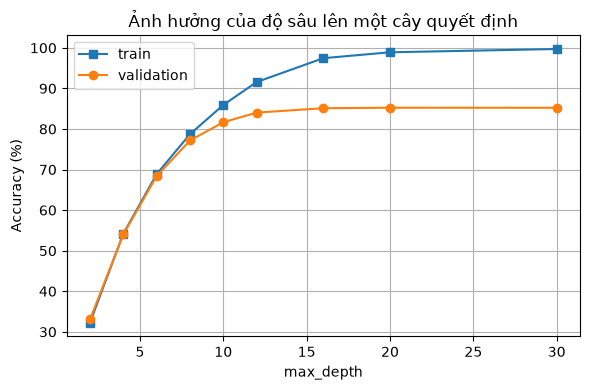

In [5]:
depths = [2, 4, 6, 8, 10, 12, 16, 20, 30]
acc_tr, acc_va = [], []
for dep in depths:
    t = DecisionTree(max_depth=dep).fit(Xtr_b, ytr)
    acc_tr.append((t.predict(Xtr_b) == ytr).mean())
    acc_va.append((t.predict(Xva_b) == yva).mean())
    print(f"max_depth={dep:2d}: train {acc_tr[-1]*100:.2f}% | val {acc_va[-1]*100:.2f}% | số lá {int((t.feature_ < 0).sum())}")

plt.figure(figsize=(6, 4))
plt.plot(depths, np.array(acc_tr) * 100, "s-", label="train")
plt.plot(depths, np.array(acc_va) * 100, "o-", label="validation")
plt.xlabel("max_depth"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(True)
plt.title("Ảnh hưởng của độ sâu lên một cây quyết định")
plt.tight_layout()
plt.savefig(p / "report" / "tree_depth.png", dpi=150)
plt.show()

In [6]:
from sklearn.tree import DecisionTreeClassifier
for name, A, B in [("pixel gốc", Xtr, Xva), ("nhị phân (>0,5)", Xtr_b, Xva_b)]:
    sk = DecisionTreeClassifier(max_depth=12, random_state=0).fit(A, ytr)
    print(name, "val acc:", (sk.predict(B) == yva).mean() * 100)

pixel gốc val acc: 87.2
nhị phân (>0,5) val acc: 84.14
